# Proyecto 1 - EDA Predict Future Sales

Brady Monroy (15003165) y Luis Rodolfo Rodriguez

Objetivo: explorar el dataset **Predict Future Sales** (1C Company) para entender su estructura, calidad y patrones
antes de construir un modelo que pronostique las ventas mensuales de cada par tienda-producto en noviembre de 2015.

## 1. Carga de librerias y datos

Los archivos de Kaggle se colocan en `data/raw/` y no se suben al repositorio (están excluidos en `.gitignore`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_style("whitegrid")

In [2]:
# Cargar los archivos
sales = pd.read_csv("../data/raw/sales_train.csv")
items = pd.read_csv("../data/raw/items.csv")
categories = pd.read_csv("../data/raw/item_categories.csv")
shops = pd.read_csv("../data/raw/shops.csv")
test = pd.read_csv("../data/raw/test.csv")

## 2. Comprension inicial del dataset

### 2a. Primeras filas de cada archivo

In [3]:
sales.head()

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00


In [4]:
items.head()

,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40


In [5]:
categories.head()

,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4


In [6]:
shops.head()

,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4


In [7]:
test.head()

,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


### 2b. Tamaño de cada tabla

In [8]:
print("sales_train     :", sales.shape)
print("items           :", items.shape)
print("item_categories :", categories.shape)
print("shops           :", shops.shape)
print("test            :", test.shape)

sales_train     : (2935849, 6)
items           : (22170, 3)
item_categories : (84, 2)
shops           : (60, 2)
test            : (214200, 3)


### 2c. Descripción de las columnas

| Columna | Tabla | Descripción |
|---|---|---|
| `date` | sales_train | Fecha de la transacción (texto `dd.mm.aaaa`). |
| `date_block_num` | sales_train | Número de mes consecutivo: 0 = enero 2013, ..., 33 = octubre 2015. |
| `shop_id` | sales_train, shops, test | Identificador de la tienda (sucursal). |
| `item_id` | sales_train, items, test | Identificador del producto. |
| `item_price` | sales_train | Precio unitario del producto en esa transacción (rublos). |
| `item_cnt_day` | sales_train | Unidades vendidas ese día; los valores negativos son devoluciones. |
| `item_name` | items | Nombre del producto (en ruso). |
| `item_category_id` | items, item_categories | Identificador de la categoría del producto. |
| `item_category_name` | item_categories | Nombre de la categoría (en ruso, formato `Grupo - Subgrupo`). |
| `shop_name` | shops | Nombre de la tienda; la primera palabra es la ciudad. |
| `ID` | test | Identificador de cada par tienda-producto a predecir. |

**Variable objetivo:** `item_cnt_month`, es decir, la suma mensual de `item_cnt_day` para cada par
(`shop_id`, `item_id`). En la competencia se evalúa recortada al rango [0, 20]. Además, se construye la variable
`revenue = item_price × item_cnt_day` para medir las ventas en dinero.

### 2d. Rango temporal

In [9]:
fechas = pd.to_datetime(sales["date"], format="%d.%m.%Y")

print("Fecha mínima:", fechas.min())
print("Fecha máxima:", fechas.max())
print("Número de meses:", sales["date_block_num"].nunique())
print("Días distintos con ventas:", fechas.nunique())

Fecha mínima: 2013-01-01 00:00:00
Fecha máxima: 2015-10-31 00:00:00
Número de meses: 34
Días distintos con ventas: 1034


**Interpretación (sección 2):**

- `sales_train` es la tabla principal: **2,935,849 transacciones diarias** en 6 columnas. Las demás tablas son
  catálogos pequeños: **22,170 productos**, **84 categorías** y **60 tiendas**.
- `test` contiene **214,200 pares tienda-producto** que deben pronosticarse para noviembre de 2015
  (`date_block_num = 34`).
- Los datos van del **1 de enero de 2013 al 31 de octubre de 2015**: **34 meses** (`date_block_num` 0 a 33)
  y **1,034 días**, que es exactamente el número de días calendario del periodo.
- Los nombres de productos, categorías y tiendas están en ruso. Para el análisis se usan sus IDs, y de los nombres
  se pueden obtener la ciudad de la tienda y el grupo de la categoría (por ejemplo, `Кино` = Cine, `Игры` = Juegos,
  `Музыка` = Música, `Подарки` = Regalos).

## 3. Validacion de la estructura de los datos

### 3a. Tipos de datos de cada variable

In [10]:
sales.dtypes

date                  str
date_block_num      int64
shop_id             int64
item_id             int64
item_price        float64
item_cnt_day      float64
dtype: object

In [11]:
print(items.dtypes, "\n")
print(categories.dtypes, "\n")
print(shops.dtypes, "\n")
print(test.dtypes)

item_name             str
item_id             int64
item_category_id    int64
dtype: object 

item_category_name      str
item_category_id      int64
dtype: object 

shop_name      str
shop_id      int64
dtype: object 

ID         int64
shop_id    int64
item_id    int64
dtype: object


### 3b. Convertir la columna `date` a tipo fecha

In [12]:
print("Tipo antes:", sales["date"].dtype)

sales["date"] = pd.to_datetime(sales["date"], format="%d.%m.%Y")

print("Tipo después:", sales["date"].dtype)
sales.head()

Tipo antes: str


Tipo después: datetime64[us]


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,2013-01-02,0,59,22154,999.00,1.00
1,2013-01-03,0,25,2552,899.00,1.00
2,2013-01-05,0,25,2552,899.00,-1.00
3,2013-01-06,0,25,2554,"1,709.05",1.00
4,2013-01-15,0,25,2555,"1,099.00",1.00


### 3c. Frecuencia temporal: días sin ventas y consistencia de `date_block_num`

In [13]:
# Todos los días del calendario entre la fecha mínima y la máxima
todos_los_dias = pd.date_range(sales["date"].min(), sales["date"].max())
dias_con_ventas = sales["date"].unique()

print("Días en el calendario:", len(todos_los_dias))
print("Días con ventas:", len(dias_con_ventas))
print("Días sin ventas:", len(todos_los_dias) - len(dias_con_ventas))

Días en el calendario: 1034
Días con ventas: 1034
Días sin ventas: 0


In [14]:
# Número de transacciones por día: ¿hay días con muy poca actividad?
transacciones_por_dia = sales.groupby("date").size()
print(transacciones_por_dia.describe())
print()
print("Días con menos transacciones:")
print(transacciones_por_dia.sort_values().head())

count   1,034.00
mean    2,839.31
std     1,165.81
min     1,123.00
25%     2,034.25
50%     2,590.50
75%     3,370.50
max     9,434.00
dtype: float64

Días con menos transacciones:
date
2015-05-12    1123
2015-05-13    1128
2015-10-06    1152
2015-04-28    1154
2015-05-14    1174
dtype: int64


In [15]:
# Calcular el número de mes a partir de la fecha y compararlo con date_block_num
mes_calculado = (sales["date"].dt.year - 2013) * 12 + sales["date"].dt.month - 1

diferencias = (mes_calculado != sales["date_block_num"]).sum()
print("Filas donde date_block_num no coincide con la fecha:", diferencias)

Filas donde date_block_num no coincide con la fecha: 0


**Interpretación (sección 3):**

- **Tipos de datos:**
  - Fecha: `date`, que venía como texto y se convirtió a `datetime64`.
  - Numéricas continuas: `item_price` y `item_cnt_day` (`float64`).
  - Categóricas codificadas como número: `shop_id`, `item_id`, `item_category_id` e `ID` (`int64`). Aunque son
    números, representan etiquetas, así que no tiene sentido sumarlas ni promediarlas.
  - Temporal ordinal: `date_block_num` (`int64`), el índice del mes.
  - Texto: `item_name`, `item_category_name` y `shop_name`.
- La conversión de `date` con el formato `%d.%m.%Y` funcionó sin errores en todas las filas.
- **No hay días sin ventas:** los 1,034 días del calendario tienen transacciones. El día con menos actividad tuvo
  1,123 transacciones (12 de mayo de 2015) y el promedio es de 2,839 por día.
- **`date_block_num` es 100% consistente con la fecha:** 0 filas no coinciden con el mes calculado a partir de `date`.
- **Frecuencia elegida: mensual.** El objetivo de la competencia es mensual (`item_cnt_month`) y a nivel de cada
  par tienda-producto la venta diaria casi siempre es 0 o 1 unidad, lo que genera series muy irregulares. La serie
  diaria total se usa solo para estudiar el ciclo semanal (secciones 6 y 9).

## 4. Valores faltantes y duplicados

### 4a. Valores nulos

In [16]:
print("sales_train:")
print(sales.isnull().sum())
print("Porcentaje de nulos:", sales.isnull().sum().sum() / len(sales) * 100, "%")
print()
print("items nulos:", items.isnull().sum().sum())
print("item_categories nulos:", categories.isnull().sum().sum())
print("shops nulos:", shops.isnull().sum().sum())
print("test nulos:", test.isnull().sum().sum())

sales_train:
date              0
date_block_num    0
shop_id           0
item_id           0
item_price        0
item_cnt_day      0
dtype: int64
Porcentaje de nulos: 0.0 %

items nulos: 0
item_categories nulos: 0
shops nulos: 0
test nulos: 0


### 4b. Valores inválidos: precios menores o iguales a cero y cantidades negativas

In [17]:
precios_malos = sales[sales["item_price"] <= 0]
print("Filas con precio <= 0:", len(precios_malos))
precios_malos

Filas con precio <= 0: 1


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.00,1.00


In [18]:
devoluciones = sales[sales["item_cnt_day"] < 0]
print("Filas con cantidad negativa (devoluciones):", len(devoluciones))
print("Porcentaje del total:", round(len(devoluciones) / len(sales) * 100, 2), "%")
print()
print(devoluciones["item_cnt_day"].value_counts())

Filas con cantidad negativa (devoluciones): 7356
Porcentaje del total: 0.25 %

item_cnt_day
-1.00     7252
-2.00       78
-3.00       14
-5.00        4
-4.00        3
-6.00        2
-22.00       1
-16.00       1
-9.00        1
Name: count, dtype: int64


### 4c. Registros duplicados

In [19]:
duplicados = sales[sales.duplicated(keep=False)]
print("Filas duplicadas (copias extra):", sales.duplicated().sum())
duplicados.sort_values(["date", "shop_id", "item_id"])

Filas duplicadas (copias extra): 6


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.00,1.00
76962,2013-01-05,0,54,20130,149.00,1.00
1435365,2014-02-23,13,50,3423,999.00,1.00
1435367,2014-02-23,13,50,3423,999.00,1.00
1496765,2014-03-23,14,21,3423,999.00,1.00
1496766,2014-03-23,14,21,3423,999.00,1.00
1671872,2014-05-01,16,50,3423,999.00,1.00
1671873,2014-05-01,16,50,3423,999.00,1.00
1866322,2014-07-12,18,25,3423,999.00,1.00
1866340,2014-07-12,18,25,3423,999.00,1.00


### 4c. Tiendas repetidas en `shops.csv`

In [20]:
# Al ordenar por nombre, las tiendas con nombres parecidos quedan juntas.
# Se quita el signo "!" del inicio para comparar.
shops["nombre_limpio"] = shops["shop_name"].str.replace("!", "").str.strip()
shops.sort_values("nombre_limpio")[["shop_id", "shop_name"]]

,shop_id,shop_name
2,2,"Адыгея ТЦ ""Мега"""
3,3,"Балашиха ТРК ""Октябрь-Киномир"""
4,4,"Волжский ТЦ ""Волга Молл"""
5,5,"Вологда ТРЦ ""Мармелад"""
6,6,"Воронеж (Плехановская, 13)"
7,7,"Воронеж ТРЦ ""Максимир"""
8,8,"Воронеж ТРЦ Сити-Парк ""Град"""
9,9,Выездная Торговля
10,10,Жуковский ул. Чкалова 39м?
11,11,Жуковский ул. Чкалова 39м²


In [21]:
# Revisar en qué meses vendió cada tienda sospechosa
sospechosas = [0, 57, 1, 58, 10, 11, 39, 40]

for tienda in sospechosas:
    meses = sales[sales["shop_id"] == tienda]["date_block_num"]
    print("Tienda", tienda, "-> vende del mes", meses.min(), "al", meses.max(),
          "| meses con ventas:", meses.nunique(), "| ¿está en test?:", tienda in test["shop_id"].values)

Tienda 0 -> vende del mes 0 al 1 | meses con ventas: 2 | ¿está en test?: False
Tienda 57 -> vende del mes 2 al 33 | meses con ventas: 32 | ¿está en test?: True
Tienda 1 -> vende del mes 0 al 1 | meses con ventas: 2 | ¿está en test?: False
Tienda 58 -> vende del mes 2 al 33 | meses con ventas: 32 | ¿está en test?: True
Tienda 10 -> vende del mes 0 al 33 | meses con ventas: 33 | ¿está en test?: True
Tienda 11 -> vende del mes 25 al 25 | meses con ventas: 1 | ¿está en test?: False
Tienda 39 -> vende del mes 14 al 33 | meses con ventas: 20 | ¿está en test?: True
Tienda 40 -> vende del mes 14 al 24 | meses con ventas: 11 | ¿está en test?: False


### Limpieza aplicada

In [22]:
df = sales.copy()

# 1) Quitar las filas duplicadas
df = df.drop_duplicates()

# 2) Quitar las filas con precio menor o igual a cero
df = df[df["item_price"] > 0]

# 3) Unir las tiendas repetidas (se usa el ID que aparece en test)
df.loc[df["shop_id"] == 0, "shop_id"] = 57
df.loc[df["shop_id"] == 1, "shop_id"] = 58
df.loc[df["shop_id"] == 11, "shop_id"] = 10

# 4) Crear la columna de ingresos
df["revenue"] = df["item_price"] * df["item_cnt_day"]

# 5) Agregar nombre de producto, categoría y tienda
df = df.merge(items, on="item_id", how="left")
df = df.merge(categories, on="item_category_id", how="left")
df = df.merge(shops[["shop_id", "shop_name"]], on="shop_id", how="left")

print("Filas antes:", len(sales))
print("Filas después:", len(df))
df.head()

Filas antes: 2935849
Filas después: 2935842


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,revenue,item_name,item_category_id,item_category_name,shop_name
0,2013-01-02,0,59,22154,999.00,1.00,999.00,ЯВЛЕНИЕ 2012 (BD),37,Кино - Blu-Ray,"Ярославль ТЦ ""Альтаир"""
1,2013-01-03,0,25,2552,899.00,1.00,899.00,DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил,"Москва ТРК ""Атриум"""
2,2013-01-05,0,25,2552,899.00,-1.00,-899.00,DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил,"Москва ТРК ""Атриум"""
3,2013-01-06,0,25,2554,"1,709.05",1.00,"1,709.05",DEEP PURPLE Who Do You Think We Are LP,58,Музыка - Винил,"Москва ТРК ""Атриум"""
4,2013-01-15,0,25,2555,"1,099.00",1.00,"1,099.00",DEEP PURPLE 30 Very Best Of 2CD (Фирм.),56,Музыка - CD фирменного производства,"Москва ТРК ""Атриум"""


**Interpretación y estrategia (sección 4):**

- **Nulos:** ninguna tabla tiene valores nulos (0%), así que no hace falta eliminar ni imputar.
- **Precio menor o igual a cero:** hay **1 sola fila** con `item_price = -1` (15 de mayo de 2013, tienda 32,
  producto 2973). Es un error de registro y se **elimina**; quitarla no afecta el análisis.
- **Cantidades negativas (devoluciones):** hay **7,356 filas (0.25%)**; casi todas son de -1 unidad (7,252).
  Se **conservan**, porque son movimientos reales y, al sumar por mes, la variable objetivo queda como venta neta
  (ventas menos devoluciones), que es lo que pide la competencia.
- **Duplicados:** hay **6 filas exactamente iguales** a otra (misma fecha, tienda, producto, precio y cantidad).
  Como son muy pocas, lo más probable es que sean registros cargados dos veces, por lo que se **elimina la copia
  extra**. El impacto es mínimo (6 de 2.9 millones de filas).
- **Tiendas repetidas en `shops.csv`:** se encontraron 3 casos con el mismo nombre y distinto ID:
  - Tienda **0** y **57** (`Якутск Орджоникидзе, 56`, la 0 con `!` y la palabra `фран`): la 0 vende solo en los
    meses 0-1 y la 57 desde el mes 2. Se une la 0 dentro de la **57**.
  - Tienda **1** y **58** (`Якутск ТЦ "Центральный"`): mismo patrón (1 en meses 0-1, 58 desde el mes 2). Se une la 1
    dentro de la **58**.
  - Tienda **10** y **11** (`Жуковский ул. Чкалова 39м`): la 11 solo vendió en el mes 25, justo el único mes que le
    falta a la 10. Se une la 11 dentro de la **10**.
  - En los tres casos se conserva el ID que aparece en `test.csv` (57, 58 y 10).
  - Las tiendas **39** y **40** tienen nombres parecidos, pero la 40 dice `Островной` (otro local) y ambas vendieron
    al mismo tiempo en los meses 14-24, por lo que se tratan como **tiendas distintas**.
- Tras la limpieza quedan **2,935,842 filas** (se quitaron 7) y se agregó la columna `revenue`.

## 5. Analisis descriptivo general

### 5a. Métricas estadísticas básicas

In [23]:
df[["item_price", "item_cnt_day", "revenue"]].agg(["mean", "median", "min", "max", "std"])

,item_price,item_cnt_day,revenue
mean,890.85,1.24,"1,157.73"
median,399.00,1.00,449.00
min,0.07,-22.00,"-68,970.00"
max,"307,980.00","2,169.00","1,829,990.00"
std,"1,729.80",2.62,"5,683.61"


### 5b-i. Distribución de ventas por producto y por categoría

In [24]:
ventas_producto = df.groupby("item_id")["item_cnt_day"].sum()

print("Productos que tuvieron alguna venta:", len(ventas_producto))
print(ventas_producto.describe())
print()
print("Productos con 10 unidades o menos en todo el periodo:", (ventas_producto <= 10).sum())

Productos que tuvieron alguna venta: 21807
count    21,807.00
mean        167.29
std       1,366.22
min         -11.00
25%           7.00
50%          33.00
75%         124.00
max     187,642.00
Name: item_cnt_day, dtype: float64

Productos con 10 unidades o menos en todo el periodo: 6709


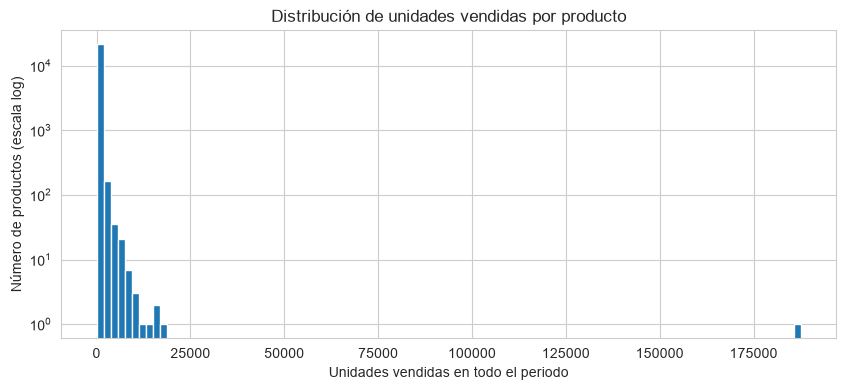

In [25]:
# Histograma en escala logarítmica porque unos pocos productos venden muchísimo
plt.figure(figsize=(10, 4))
plt.hist(ventas_producto[ventas_producto > 0], bins=100, log=True)
plt.title("Distribución de unidades vendidas por producto")
plt.xlabel("Unidades vendidas en todo el periodo")
plt.ylabel("Número de productos (escala log)")
plt.show()

In [26]:
ventas_categoria = df.groupby("item_category_name")[["item_cnt_day", "revenue"]].sum()
ventas_categoria = ventas_categoria.sort_values("item_cnt_day", ascending=False)

print("Categorías con ventas:", len(ventas_categoria))
ventas_categoria.head(10)

Categorías con ventas: 84


,item_cnt_day,revenue
item_category_name,,
Кино - DVD,"634,170.00","169,944,072.69"
Игры PC - Стандартные издания,"456,540.00","257,519,291.08"
Музыка - CD локального производства,"348,591.00","100,022,563.57"
Игры - PS3,"254,886.00","412,050,281.90"
Кино - Blu-Ray,"203,283.00","90,478,232.84"
"Подарки - Сумки, Альбомы, Коврики д/мыши","187,998.00","934,206.61"
Игры PC - Дополнительные издания,"174,954.00","136,419,148.64"
Игры - XBOX 360,"169,940.00","259,615,132.35"
Игры - PS4,"127,319.00","373,010,312.01"


### 5b-ii. Distribución de ventas por sucursal

In [27]:
ventas_tienda = df.groupby(["shop_id", "shop_name"])[["item_cnt_day", "revenue"]].sum()
ventas_tienda = ventas_tienda.sort_values("item_cnt_day", ascending=False)

print(ventas_tienda["item_cnt_day"].describe())
ventas_tienda.head(10)

count        57.00
mean     64,003.49
std      58,418.87
min         330.00
25%      25,838.00
50%      53,886.00
75%      71,201.00
max     310,777.00
Name: item_cnt_day, dtype: float64


,,item_cnt_day,revenue
shop_id,shop_name,,
31,"Москва ТЦ ""Семеновский""","310,777.00","235,217,019.05"
25,"Москва ТРК ""Атриум""","241,919.00","216,479,572.44"
54,"Химки ТЦ ""Мега""","185,789.00","141,939,524.00"
28,"Москва ТЦ ""МЕГА Теплый Стан"" II","184,557.00","159,746,337.38"
57,"Якутск Орджоникидзе, 56","152,812.00","119,637,153.53"
42,"СПб ТК ""Невский Центр""","144,933.00","151,916,533.55"
27,"Москва ТЦ ""МЕГА Белая Дача II""","136,657.00","140,632,474.12"
6,"Воронеж (Плехановская, 13)","100,489.00","98,067,453.80"
58,"Якутск ТЦ ""Центральный""","88,045.00","71,975,824.83"


### 5b-iii. Distribución de ventas por periodo de tiempo

In [28]:
# Por día
ventas_dia = df.groupby("date")["item_cnt_day"].sum()
print("Unidades por día:")
print(ventas_dia.describe())

Unidades por día:
count    1,034.00
mean     3,528.24
std      1,584.68
min      1,274.00
25%      2,472.25
50%      3,145.00
75%      4,257.00
max     13,343.00
Name: item_cnt_day, dtype: float64


In [29]:
# Por semana
ventas_semana = df.groupby(pd.Grouper(key="date", freq="W"))["item_cnt_day"].sum()
print("Unidades por semana:")
print(ventas_semana.describe())

Unidades por semana:
count      148.00
mean    24,649.99
std      7,862.26
min     12,389.00
25%     19,889.75
50%     24,500.50
75%     27,844.75
max     57,680.00
Name: item_cnt_day, dtype: float64


In [30]:
# Por mes
ventas_mes = df.groupby("date_block_num")[["item_cnt_day", "revenue"]].sum()
print("Unidades por mes:")
print(ventas_mes["item_cnt_day"].describe())

Unidades por mes:
count        34.00
mean    107,299.97
std      28,455.95
min      63,187.00
25%      85,968.25
50%     107,306.00
75%     125,358.50
max     183,342.00
Name: item_cnt_day, dtype: float64


In [31]:
# Por año (2015 solo tiene 10 meses)
df["year"] = df["date"].dt.year
ventas_anio = df.groupby("year")[["item_cnt_day", "revenue"]].sum()
ventas_anio["meses"] = df.groupby("year")["date_block_num"].nunique()
ventas_anio["promedio_mensual_unidades"] = ventas_anio["item_cnt_day"] / ventas_anio["meses"]
ventas_anio

,item_cnt_day,revenue,meses,promedio_mensual_unidades
year,,,,
2013,"1,562,731.00","1,217,524,585.98",12,"130,227.58"
2014,"1,320,884.00","1,346,773,983.81",12,"110,073.67"
2015,"764,584.00","834,623,131.78",10,"76,458.40"


**Interpretación (sección 5):**

**a. Métricas básicas**

| Variable | Media | Mediana | Mínimo | Máximo | Desv. estándar |
|---|---|---|---|---|---|
| `item_price` | 890.85 | 399.00 | 0.07 | 307,980.00 | 1,729.80 |
| `item_cnt_day` | 1.24 | 1.00 | -22 | 2,169 | 2.62 |
| `revenue` | 1,157.73 | 449.00 | -68,970.00 | 1,829,990.00 | 5,683.61 |

- En las tres variables la **media es mucho mayor que la mediana** y el máximo está muy lejos del resto: las
  distribuciones tienen una cola larga hacia la derecha, causada por unos pocos valores extremos (ver sección 7c).
- La transacción típica es de **1 unidad** de un producto de unos **399 rublos**.

**b-i. Por producto y categoría**

- 21,807 productos tuvieron al menos un registro. La mediana es de solo **33 unidades** en casi 3 años y
  **6,709 productos (31%) vendieron 10 unidades o menos**: la gran mayoría de productos vende muy poco.
- Un solo producto domina: el **20949** (bolsa de compras de la marca, `Фирменный пакет майка`) con **187,642
  unidades**, más de 10 veces el segundo lugar. Por eso aparece aislado a la derecha del histograma.
- Las 84 categorías tienen ventas. Por unidades lideran **Cine DVD** (634,170), **Juegos PC estándar** (456,540) y
  **Música CD local** (348,591). Por ingresos lideran las consolas: **Juegos PS3** (412 millones de rublos) y
  **Juegos PS4** (373 millones), porque tienen precios más altos.

**b-ii. Por sucursal**

- Las 57 tiendas (después de unir las repetidas) tienen una mediana de **53,886 unidades**. La más grande es la
  **31** (Moscú, `Семеновский`) con **310,777**, seguida de la **25** (Moscú, `Атриум`) con 241,919. Las 7 tiendas con
  más ventas están en Moscú y alrededores, Yakutsk y San Petersburgo.

**b-iii. Por periodo**

- **Día:** promedio de **3,528 unidades** (mínimo 1,274, máximo 13,343).
- **Semana:** promedio de **24,650 unidades**.
- **Mes:** promedio de **107,300 unidades** (mínimo 63,187, máximo 183,342).
- **Año:** el promedio mensual baja de **130,228** unidades en 2013 a **110,074** en 2014 y **76,458** en 2015
  (10 meses). Los ingresos no caen al mismo ritmo (1,218 millones en 2013 y 1,347 millones en 2014), lo que indica
  que se venden menos unidades pero a mayor precio promedio.

## 6. Exploracion temporal

### 6a. Evolución de las ventas en el tiempo

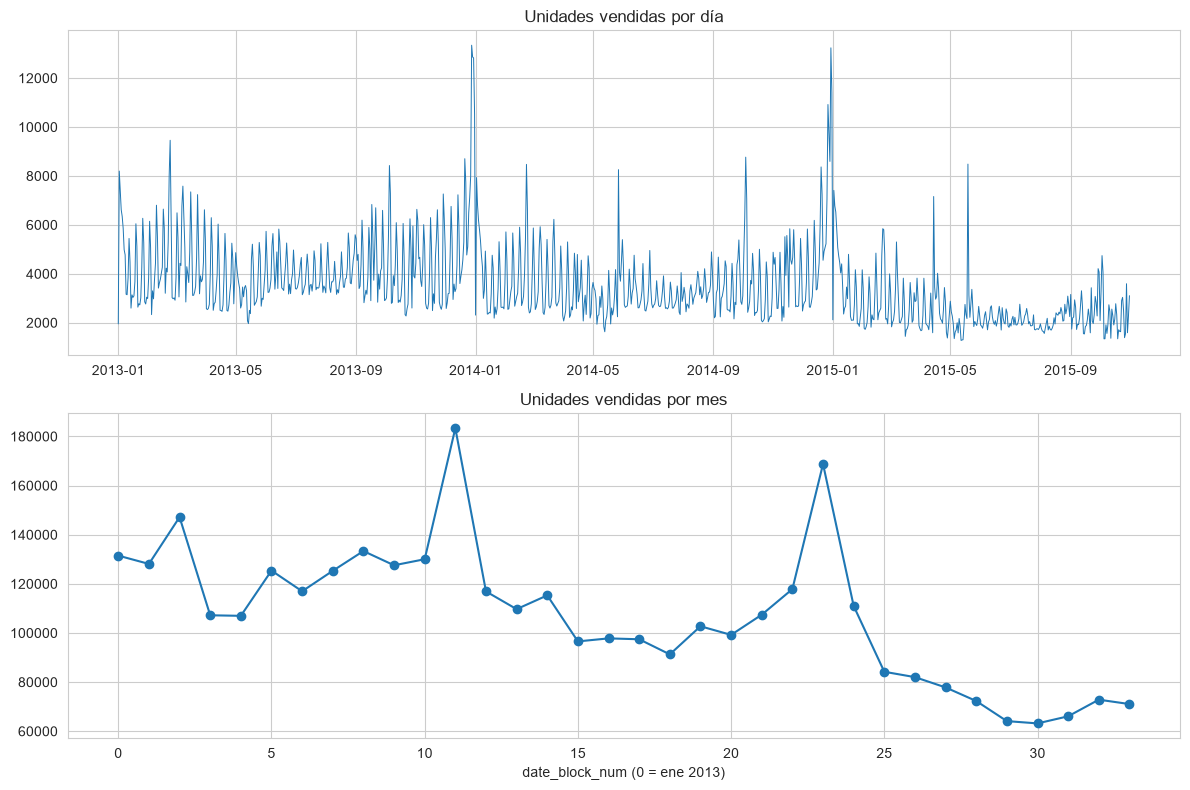

In [32]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(ventas_dia.index, ventas_dia.values, linewidth=0.7)
ax[0].set_title("Unidades vendidas por día")

ax[1].plot(ventas_mes.index, ventas_mes["item_cnt_day"], marker="o")
ax[1].set_title("Unidades vendidas por mes")
ax[1].set_xlabel("date_block_num (0 = ene 2013)")

plt.tight_layout()
plt.show()

### 6b-i. Tendencia

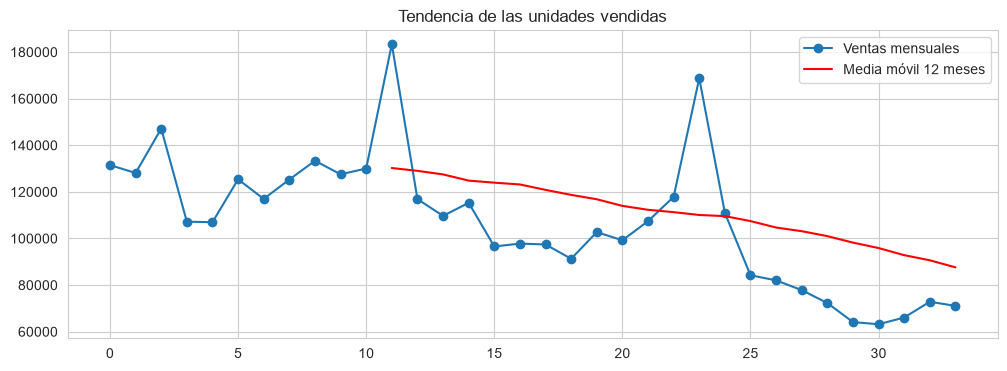

date_block_num
11   130,227.58
12   129,012.67
13   127,479.00
14   124,825.17
15   123,939.00
16   123,174.00
17   120,844.67
18   118,704.08
19   116,823.25
20   113,979.58
21   112,303.00
22   111,289.33
23   110,073.67
24   109,579.67
25   107,455.67
26   104,682.17
27   103,121.42
28   100,996.92
29    98,220.67
30    95,879.67
31    92,826.17
32    90,629.08
33    87,598.58
Name: item_cnt_day, dtype: float64


In [33]:
# Media móvil de 12 meses para ver la tendencia sin la estacionalidad
media_movil = ventas_mes["item_cnt_day"].rolling(12).mean()

plt.figure(figsize=(12, 4))
plt.plot(ventas_mes.index, ventas_mes["item_cnt_day"], marker="o", label="Ventas mensuales")
plt.plot(ventas_mes.index, media_movil, color="red", label="Media móvil 12 meses")
plt.title("Tendencia de las unidades vendidas")
plt.legend()
plt.show()

print(media_movil.dropna())

### 6b-ii. Estacionalidad

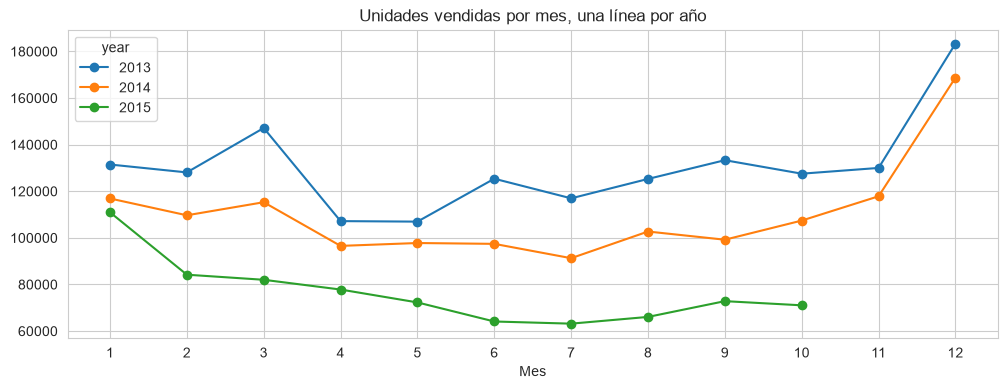

year,2013,2014,2015
month,,,
1,"131,478.00","116,899.00","110,971.00"
2,"128,090.00","109,686.00","84,198.00"
3,"147,142.00","115,296.00","82,014.00"
4,"107,190.00","96,556.00","77,827.00"
5,"106,969.00","97,789.00","72,295.00"
6,"125,381.00","97,429.00","64,114.00"
7,"116,966.00","91,279.00","63,187.00"
8,"125,291.00","102,721.00","66,079.00"
9,"133,332.00","99,208.00","72,843.00"


In [34]:
# Comparar los mismos meses en cada año
df["month"] = df["date"].dt.month
mes_anio = df.groupby(["year", "month"])["item_cnt_day"].sum().unstack(level=0)

mes_anio.plot(marker="o", figsize=(12, 4))
plt.title("Unidades vendidas por mes, una línea por año")
plt.xlabel("Mes")
plt.xticks(range(1, 13))
plt.show()

mes_anio

### 6b-iii. Picos o caídas abruptas

In [35]:
print("Días con más unidades vendidas:")
print(ventas_dia.sort_values(ascending=False).head(10))
print()
print("Días con menos unidades vendidas:")
print(ventas_dia.sort_values().head(10))

Días con más unidades vendidas:
date
2013-12-28   13,343.00
2014-12-30   13,236.00
2013-12-29   12,863.00
2013-12-30   12,823.00
2014-12-31   11,393.00
2014-12-27   10,919.00
2013-12-31   10,514.00
2014-12-28    9,727.00
2013-02-23    9,456.00
2014-10-04    8,767.00
Name: item_cnt_day, dtype: float64

Días con menos unidades vendidas:
date
2015-05-12   1,274.00
2015-05-13   1,294.00
2015-05-14   1,302.00
2015-10-05   1,340.00
2015-10-19   1,341.00
2015-10-06   1,343.00
2015-05-05   1,349.00
2015-10-12   1,363.00
2015-04-28   1,374.00
2015-10-26   1,387.00
Name: item_cnt_day, dtype: float64


In [36]:
# Cambio porcentual de un mes al siguiente
cambio = ventas_mes["item_cnt_day"].pct_change() * 100
print("Mayores subidas (%):")
print(cambio.sort_values(ascending=False).head(5))
print()
print("Mayores caídas (%):")
print(cambio.sort_values().head(5))

Mayores subidas (%):
date_block_num
23   43.20
11   41.02
5    17.21
2    14.87
19   12.54
Name: item_cnt_day, dtype: float64

Mayores caídas (%):
date_block_num
12   -36.24
24   -34.24
3    -27.15
25   -24.13
15   -16.25
Name: item_cnt_day, dtype: float64


### 6b-iv. Ciclos por día de la semana y por mes del año

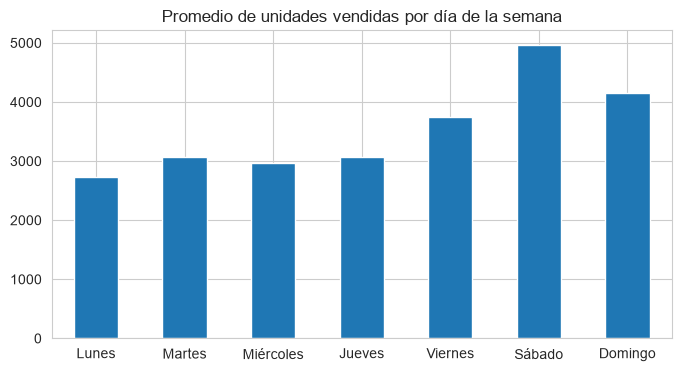

Lunes       2,731.20
Martes      3,074.22
Miércoles   2,971.03
Jueves      3,071.77
Viernes     3,739.56
Sábado      4,963.82
Domingo     4,144.84
Name: unidades, dtype: float64

In [37]:
nombres_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

tabla_dias = ventas_dia.to_frame("unidades")
tabla_dias["dia_semana"] = tabla_dias.index.dayofweek
promedio_dia_semana = tabla_dias.groupby("dia_semana")["unidades"].mean()
promedio_dia_semana.index = nombres_dias

promedio_dia_semana.plot(kind="bar", figsize=(8, 4))
plt.title("Promedio de unidades vendidas por día de la semana")
plt.xticks(rotation=0)
plt.show()

promedio_dia_semana

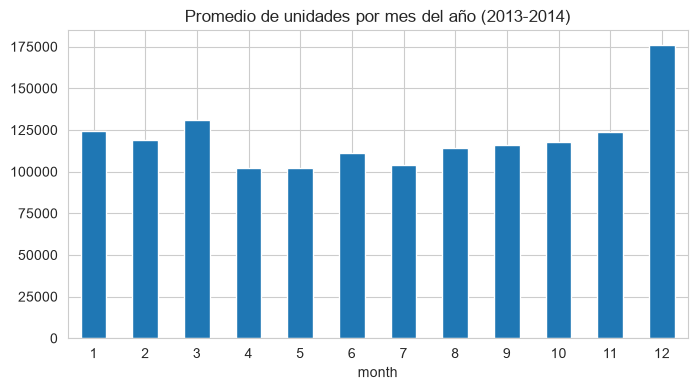

month
1    124,188.50
2    118,888.00
3    131,219.00
4    101,873.00
5    102,379.00
6    111,405.00
7    104,122.50
8    114,006.00
9    116,270.00
10   117,481.50
11   123,927.00
12   176,048.00
dtype: float64

In [38]:
# Promedio por mes del año (solo 2013 y 2014, que tienen los 12 meses completos)
promedio_mes = mes_anio[[2013, 2014]].mean(axis=1)

promedio_mes.plot(kind="bar", figsize=(8, 4))
plt.title("Promedio de unidades por mes del año (2013-2014)")
plt.xticks(rotation=0)
plt.show()

promedio_mes

**Interpretación (sección 6):**

- **Tendencia (i):** las ventas en unidades **bajan de forma sostenida**. La media móvil de 12 meses pasa de
  **130,228** (mes 11) a **87,599** (mes 33), una caída de aproximadamente **33%** en dos años.
- **Estacionalidad (ii):** el patrón anual se repite. **Diciembre es por mucho el mes más fuerte**
  (183,342 unidades en 2013 y 168,754 en 2014), mientras que de abril a julio están los meses más bajos. En
  promedio 2013-2014, diciembre vende **176,048** unidades frente a unas **102,000** en abril-mayo.
- **Picos y caídas abruptas (iii):**
  - Las mayores subidas de un mes al siguiente son noviembre→diciembre (**+41% en 2013** y **+43% en 2014**).
  - Las mayores caídas son justo después: diciembre→enero (**-36% en 2014** y **-34% en 2015**).
  - Los 8 días con más ventas son del 27 al 31 de diciembre de 2013 y 2014 (hasta **13,343 unidades** el 28 de
    diciembre de 2013). También destaca el 23 de febrero de 2013 (9,456), que es feriado en Rusia.
  - Los días con menos ventas son de **2015** (mayo y octubre, unas 1,300 unidades), lo cual es coherente con la
    tendencia a la baja.
  - En marzo de 2013 (mes 2) hay un pico que no se repite en los años siguientes.
- **Ciclos (iv):**
  - **Día de la semana:** el **sábado** es el día más fuerte (4,964 unidades en promedio), seguido del domingo
    (4,145) y el viernes (3,740). El **lunes** es el más bajo (2,731). El sábado vende en promedio un 82% más que el
    lunes.
  - **Mes del año:** además de diciembre, enero y marzo son relativamente altos, y abril, mayo y julio son los más
    bajos.

## 7. Analisis comparativo entre sucursales y productos

### 7a. Productos y categorías más y menos vendidos

In [39]:
productos = df.groupby(["item_id", "item_name"])["item_cnt_day"].sum().sort_values(ascending=False)

print("10 productos MÁS vendidos:")
print(productos.head(10))

10 productos MÁS vendidos:
item_id  item_name                                                     
20949    Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм            187,642.00
2808     Diablo III [PC, Jewel, русская версия]                            17,245.00
3732     Grand Theft Auto V [PS3, русские субтитры]                        16,642.00
17717    Прием денежных средств для 1С-Онлайн                              15,830.00
5822     Playstation Store пополнение бумажника: Карта оплаты 1000 руб.    14,515.00
3734     Grand Theft Auto V [Xbox 360, русские субтитры]                   11,688.00
6675     Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01)           10,289.00
3731     Grand Theft Auto V [PC, русские субтитры]                         10,099.00
1855     Battlefield 4 [PC, русская версия]                                10,032.00
16787    Одни из нас [PS3, русская версия]                                  9,227.00
Name: item_cnt_day, dtype: float64


In [40]:
print("10 productos MENOS vendidos (con ventas netas mayores a 0):")
print(productos[productos > 0].tail(10))
print()
print("Productos con ventas netas <= 0 (más devoluciones que ventas):", (productos <= 0).sum())

10 productos MENOS vendidos (con ventas netas mayores a 0):
item_id  item_name                                                                                           
10232    Веселая мастерская Болека и Лёлека [PC, Цифровая версия]                                               1.00
12854    КРАЙ (регион)                                                                                          1.00
10196    Ведьмак 2. Убийцы королей. Коллекционное издание [Xbox 360, русская версия]                            1.00
12867    КРАСНАЯ ПЛЕСЕНЬ  Великие исполнители XXI века  LP                                                      1.00
1822     BattleForge (online) (рус.в.) (PC-DVD) (DVD-box)                                                       1.00
1797     Batman: Arkham Origins. Initiation (дополнение) [PC, Цифровая версия]                                  1.00
1805     Batman: Аркхем Сити Day One Edition. Специальное издание для 1С Интерес (с поддержкой 3D) [PS3, русс   1.00
1806     Ba

In [41]:
print("5 categorías MÁS vendidas:")
print(ventas_categoria["item_cnt_day"].head(5))
print()
print("5 categorías MENOS vendidas:")
print(ventas_categoria["item_cnt_day"].tail(5))

5 categorías MÁS vendidas:
item_category_name
Кино - DVD                            634,170.00
Игры PC - Стандартные издания         456,540.00
Музыка - CD локального производства   348,591.00
Игры - PS3                            254,886.00
Кино - Blu-Ray                        203,283.00
Name: item_cnt_day, dtype: float64

5 categorías MENOS vendidas:
item_category_name
Книги - Открытки                    3.00
Книги - Художественная литература   3.00
Аксессуары - PS2                    2.00
Игровые консоли - PS2               1.00
Книги - Познавательная литература   1.00
Name: item_cnt_day, dtype: float64


### 7b. Comparación entre sucursales

In [42]:
resumen_tiendas = df.groupby(["shop_id", "shop_name"]).agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("revenue", "sum"),
    meses_activos=("date_block_num", "nunique"),
    primer_mes=("date_block_num", "min"),
    ultimo_mes=("date_block_num", "max"),
)
resumen_tiendas["unidades_por_mes"] = resumen_tiendas["unidades"] / resumen_tiendas["meses_activos"]
resumen_tiendas = resumen_tiendas.sort_values("unidades", ascending=False)
resumen_tiendas

,,unidades,ingresos,meses_activos,primer_mes,ultimo_mes,unidades_por_mes
shop_id,shop_name,,,,,,
31,"Москва ТЦ ""Семеновский""","310,777.00","235,217,019.05",34,0,33,"9,140.50"
25,"Москва ТРК ""Атриум""","241,919.00","216,479,572.44",34,0,33,"7,115.26"
54,"Химки ТЦ ""Мега""","185,789.00","141,939,524.00",28,0,27,"6,635.32"
28,"Москва ТЦ ""МЕГА Теплый Стан"" II","184,557.00","159,746,337.38",34,0,33,"5,428.15"
57,"Якутск Орджоникидзе, 56","152,812.00","119,637,153.53",34,0,33,"4,494.47"
42,"СПб ТК ""Невский Центр""","144,933.00","151,916,533.55",34,0,33,"4,262.74"
27,"Москва ТЦ ""МЕГА Белая Дача II""","136,657.00","140,632,474.12",32,0,32,"4,270.53"
6,"Воронеж (Плехановская, 13)","100,489.00","98,067,453.80",34,0,33,"2,955.56"
58,"Якутск ТЦ ""Центральный""","88,045.00","71,975,824.83",34,0,33,"2,589.56"


In [43]:
print("Tiendas que dejaron de vender antes de octubre 2015 (mes 33):")
print(resumen_tiendas[resumen_tiendas["ultimo_mes"] < 33][["meses_activos", "primer_mes", "ultimo_mes"]])

Tiendas que dejaron de vender antes de octubre 2015 (mes 33):
                                                         meses_activos  \
shop_id shop_name                                                        
54      Химки ТЦ "Мега"                                             28   
27      Москва ТЦ "МЕГА Белая Дача II"                              32   
30      Москва ТЦ "Перловский"                                      26   
29      Москва ТЦ "Новый век" (Новокосино)                          29   
43      СПб ТК "Сенная"                                             25   
51      Тюмень ТЦ "Зеленый Берег"                                   33   
17      Красноярск ТЦ "Взлетка Плаза"                               20   
13      Казань ТЦ "Бехетле"                                         20   
32      Москва ТЦ "Серебряный Дом"                                   7   
23      Москва ТК "Буденовский" (пав.А2)                             4   
33      Мытищи ТРК "XL-3"                         

### 7c. Outliers y comportamientos anómalos

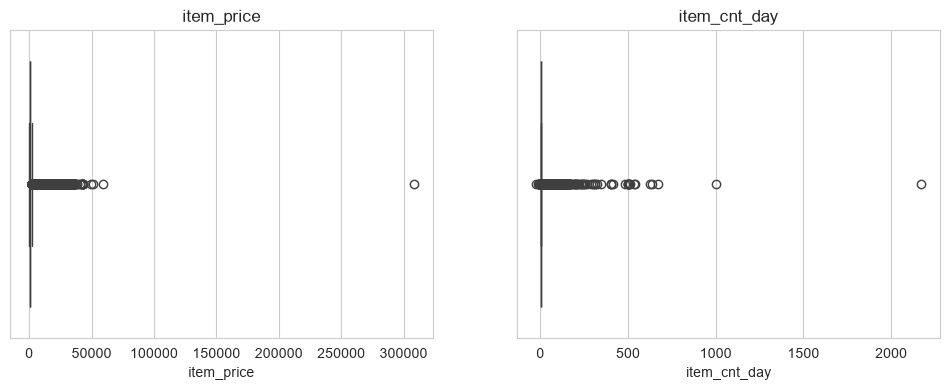

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["item_price"], ax=ax[0])
ax[0].set_title("item_price")
sns.boxplot(x=df["item_cnt_day"], ax=ax[1])
ax[1].set_title("item_cnt_day")
plt.show()

In [45]:
print("Transacciones con el precio más alto:")
df.sort_values("item_price", ascending=False)[["date", "shop_id", "item_id", "item_name", "item_price", "item_cnt_day"]].head(5)

Transacciones con el precio más alto:


,date,shop_id,item_id,item_name,item_price,item_cnt_day
1163156,2013-12-13,12,6066,Radmin 3 - 522 лиц.,"307,980.00",1.00
885136,2013-09-17,12,11365,Доставка (EMS),"59,200.00",1.00
1488132,2014-03-20,25,13199,Коллекционные шахматы (Властелин Колец),"50,999.00",1.00
2327152,2015-01-29,12,7241,UserGate Proxy & Firewall 6.X с модулем фильтр...,"49,782.00",1.00
2885685,2015-10-23,42,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...","42,990.00",1.00


In [46]:
print("Transacciones con más unidades en un día:")
df.sort_values("item_cnt_day", ascending=False)[["date", "shop_id", "item_id", "item_name", "item_price", "item_cnt_day"]].head(5)

Transacciones con más unidades en un día:


,date,shop_id,item_id,item_name,item_price,item_cnt_day
2909811,2015-10-28,12,11373,Доставка до пункта выдачи (Boxberry),0.91,"2,169.00"
2326923,2015-01-15,12,20949,Фирменный пакет майка 1С Интерес белый (34*42)...,4.00,"1,000.00"
2864228,2015-09-30,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...","1,692.53",669.00
2851084,2015-09-30,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...","1,702.83",637.00
2608033,2015-04-14,12,3731,"Grand Theft Auto V [PC, русские субтитры]","1,904.55",624.00


In [47]:
# Regla del rango intercuartílico (IQR) para contar outliers
for columna in ["item_price", "item_cnt_day"]:
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    cantidad = (df[columna] > limite_superior).sum()
    print(columna, "-> límite superior:", limite_superior, "| filas por encima:", cantidad,
          "(", round(cantidad / len(df) * 100, 2), "% )")

item_price -> límite superior: 2124.0 | filas por encima: 258942 ( 8.82 % )
item_cnt_day -> límite superior: 1.0 | filas por encima: 299121 ( 10.19 % )


**Interpretación (sección 7):**

**a. Más y menos vendidos**

- **Productos más vendidos:** el 20949 (bolsa de la marca) con 187,642 unidades, seguido de videojuegos como
  *Diablo III* para PC (17,245), *Grand Theft Auto V* para PS3 (16,642), Xbox 360 (11,688) y PC (10,099), y
  *Battlefield 4* (10,032). También aparecen productos que no son mercancía física: el 17717 (`Прием денежных средств
  для 1С-Онлайн`, recepción de pagos en línea, 15,830) y una tarjeta de recarga de PlayStation Store (14,515), además
  de la consola PS4 (10,289).
- **Productos menos vendidos:** muchos productos vendieron **1 sola unidad** en todo el periodo, y **8 productos tienen
  ventas netas de 0 o negativas** (más devoluciones que ventas).
- **Categorías más vendidas:** Cine DVD, Juegos PC estándar, Música CD local, Juegos PS3 y Cine Blu-Ray.
- **Categorías menos vendidas:** algunas de Libros (`Книги`) y las de PS2 (accesorios y consola), con 1 a 3 unidades
  en total.

**b. Sucursales**

- Hay una gran diferencia entre tiendas: la 31 vende **310,777** unidades y la 36 apenas **330**.
- La tienda **36** solo tiene ventas en el **mes 33** (octubre 2015): es una tienda nueva, y está en `test`.
- **13 tiendas dejaron de vender antes de octubre 2015**, entre ellas algunas grandes como la 54 (`Химки`, último mes
  27) y la 27 (`МЕГА Белая Дача II`, último mes 32). Ninguna de las 13 aparece en `test`.
- Al comparar unidades por mes activo se evita castigar a las tiendas que abrieron tarde o cerraron antes.

**c. Outliers y comportamientos anómalos**

- **Precio:** la transacción más cara es de **307,980 rublos** (producto 6066, `Radmin 3 - 522 лиц.`, una licencia de
  software para 522 usuarios, vendida en la tienda 12). Es un valor real pero excepcional: el siguiente precio más
  alto es de 59,200.
- **Cantidad:** el máximo es de **2,169 unidades en un día** (producto 11373, `Доставка до пункта выдачи`, un servicio
  de envío, con precio de 0.91). También hay 1,000 unidades del producto 20949 (la bolsa) en un día.
- De las 10 transacciones extremas mostradas (5 por precio y 5 por cantidad), **7 son de la tienda 12**
  (`Интернет-магазин ЧС`, tienda en línea) y 1 de la **55** (`Цифровой склад 1С-Онлайн`, almacén digital). Estas
  tiendas se comportan distinto a las tiendas físicas.
- La regla IQR marca **8.82%** de los precios y **10.19%** de las cantidades como outliers. En el caso de la
  cantidad la regla no es útil: como casi todas las ventas son de 1 unidad, el límite queda en 1 y cualquier venta de
  2 o más unidades se marca como outlier.
- **Decisión:** en este EDA no se eliminan los outliers. Para el modelo se recomienda recortar la variable objetivo
  a [0, 20] (como pide la competencia) y revisar si conviene excluir los productos de servicio (envíos, pagos,
  bolsas) que no son ventas comparables.

## 8. Visualizaciones clave

### 8a. Serie de tiempo de ventas totales

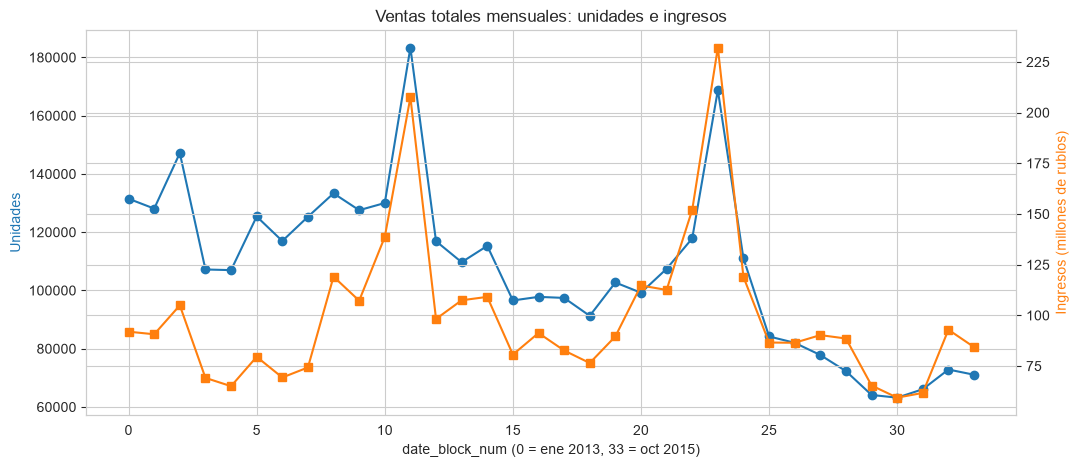

In [48]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(ventas_mes.index, ventas_mes["item_cnt_day"], marker="o", color="tab:blue")
ax1.set_ylabel("Unidades", color="tab:blue")
ax1.set_xlabel("date_block_num (0 = ene 2013, 33 = oct 2015)")

ax2 = ax1.twinx()
ax2.plot(ventas_mes.index, ventas_mes["revenue"] / 1000000, marker="s", color="tab:orange")
ax2.set_ylabel("Ingresos (millones de rublos)", color="tab:orange")

plt.title("Ventas totales mensuales: unidades e ingresos")
plt.show()

### 8b. Ventas por sucursal

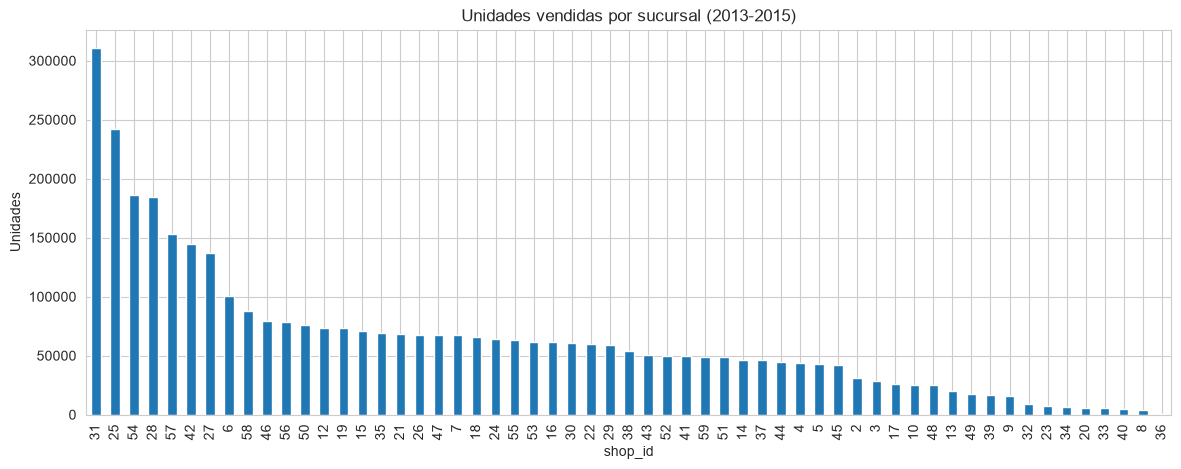

In [49]:
unidades_tienda = df.groupby("shop_id")["item_cnt_day"].sum().sort_values(ascending=False)

plt.figure(figsize=(14, 5))
unidades_tienda.plot(kind="bar")
plt.title("Unidades vendidas por sucursal (2013-2015)")
plt.xlabel("shop_id")
plt.ylabel("Unidades")
plt.show()

### 8c. Ventas por producto (top 20) y por categoría

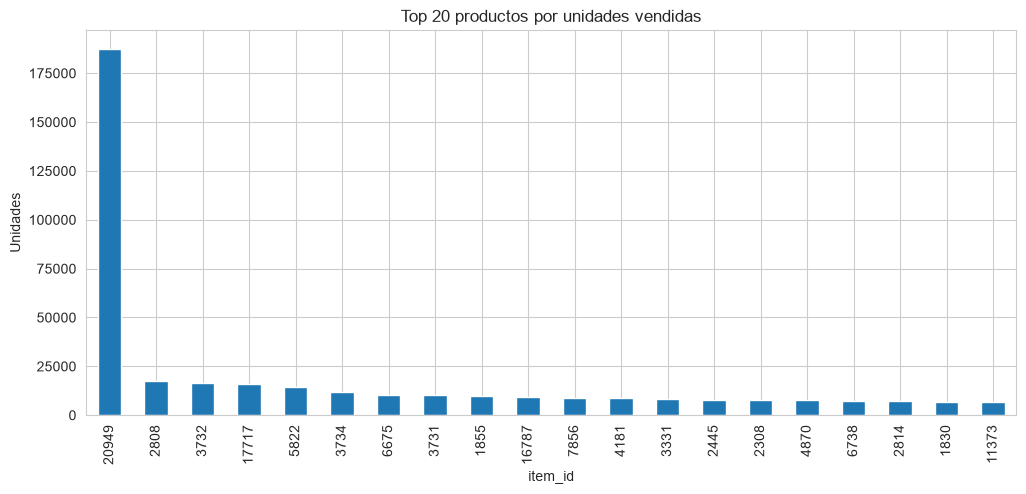

In [50]:
top20 = df.groupby("item_id")["item_cnt_day"].sum().sort_values(ascending=False).head(20)

plt.figure(figsize=(12, 5))
top20.plot(kind="bar")
plt.title("Top 20 productos por unidades vendidas")
plt.xlabel("item_id")
plt.ylabel("Unidades")
plt.show()

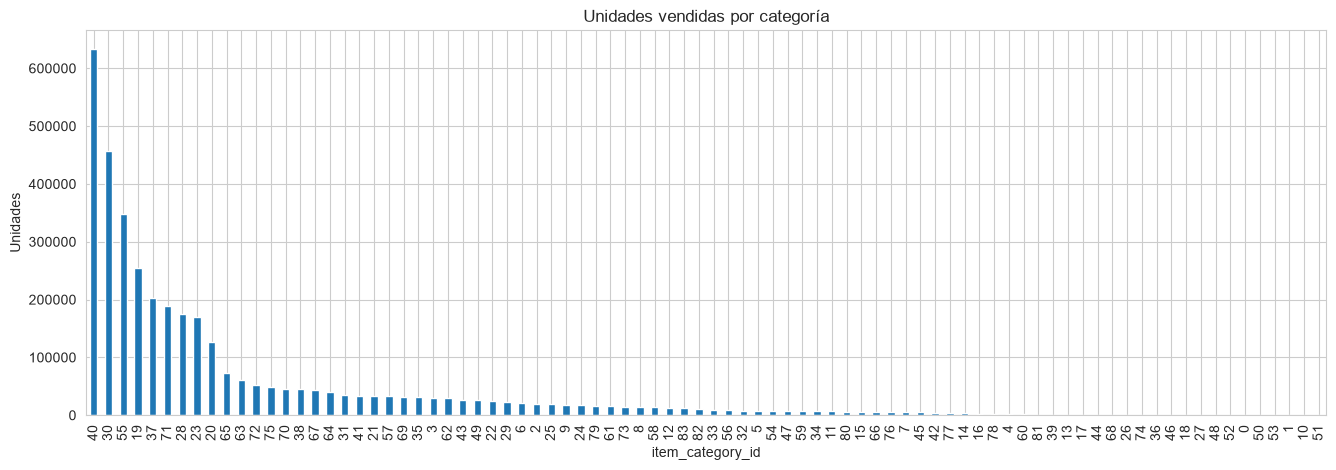

In [51]:
unidades_categoria = df.groupby("item_category_id")["item_cnt_day"].sum().sort_values(ascending=False)

plt.figure(figsize=(16, 5))
unidades_categoria.plot(kind="bar")
plt.title("Unidades vendidas por categoría")
plt.xlabel("item_category_id")
plt.ylabel("Unidades")
plt.show()

### 8d. Heatmaps: ventas en el tiempo por sucursal y por categoría

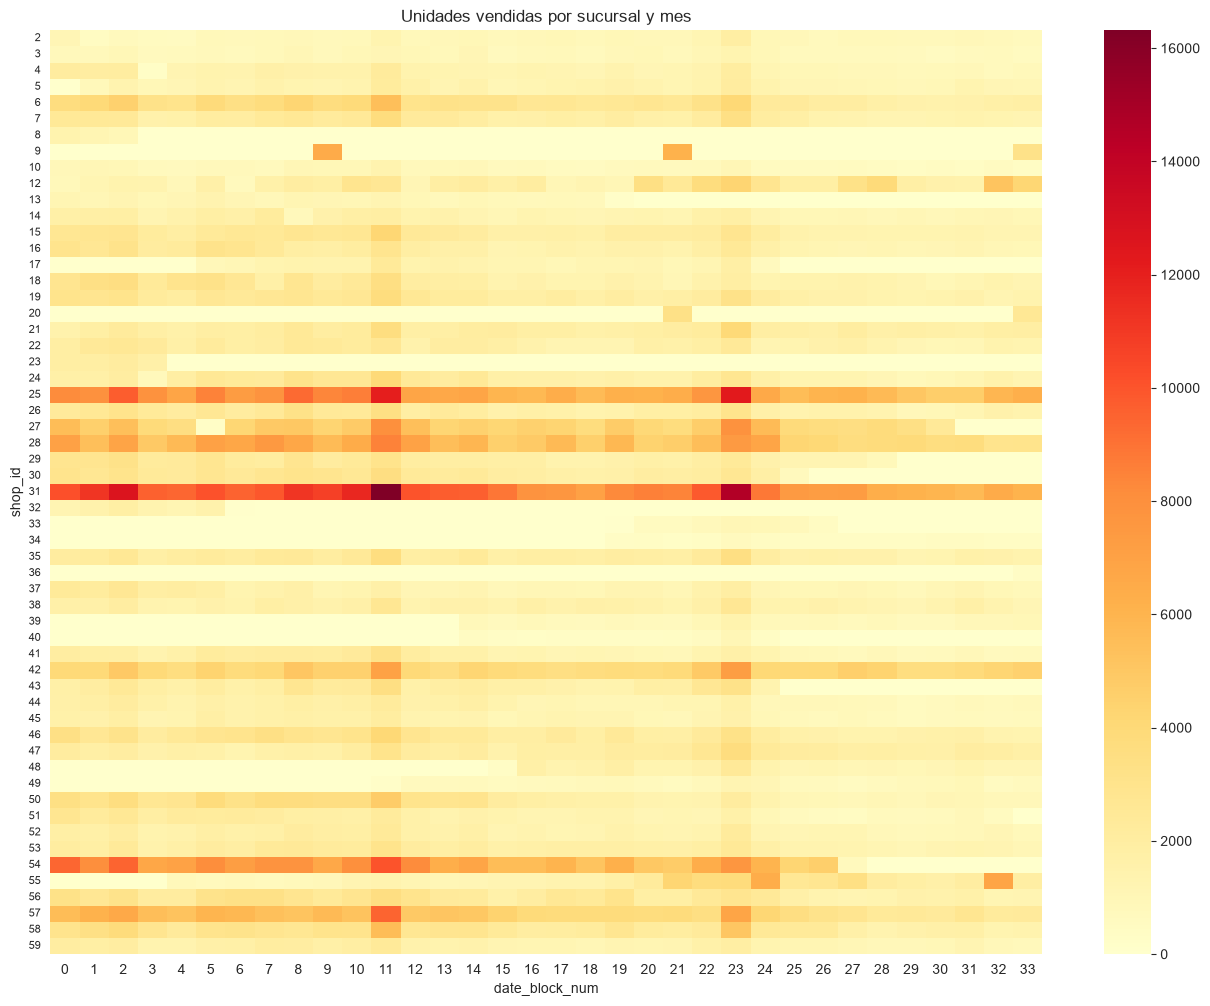

In [52]:
matriz_tienda = df.pivot_table(index="shop_id", columns="date_block_num",
                               values="item_cnt_day", aggfunc="sum", fill_value=0)

plt.figure(figsize=(16, 12))
sns.heatmap(matriz_tienda, cmap="YlOrRd", yticklabels=True)
plt.yticks(fontsize=8, rotation=0)
plt.title("Unidades vendidas por sucursal y mes")
plt.xlabel("date_block_num")
plt.show()

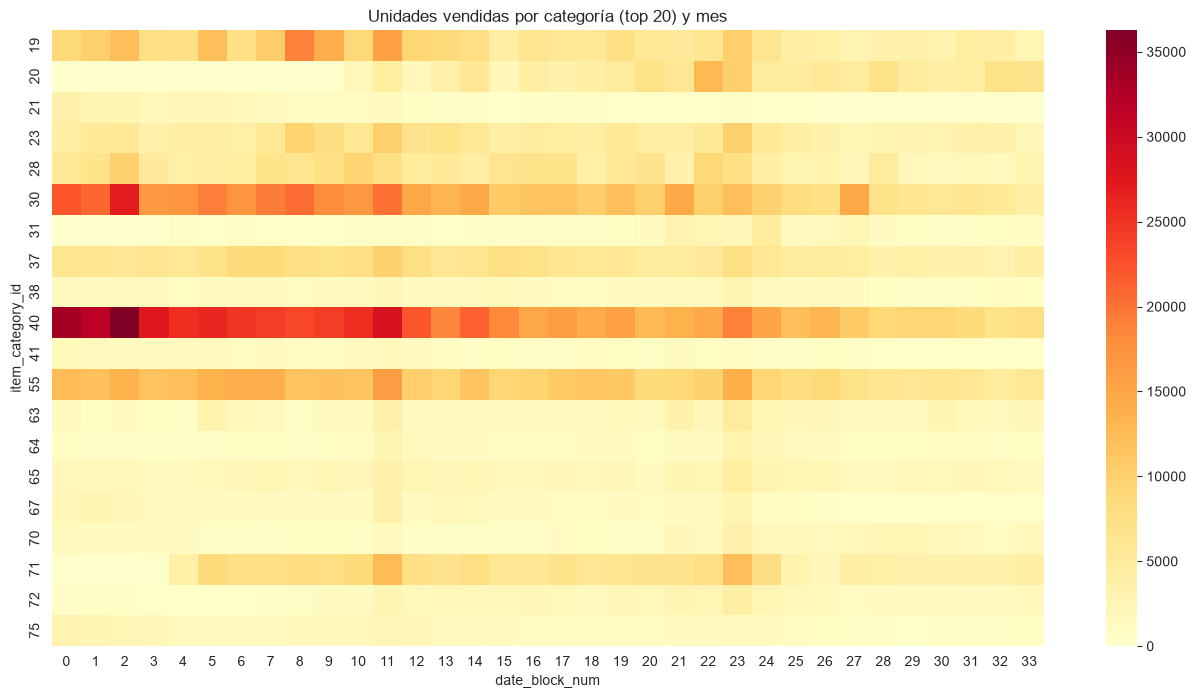

In [53]:
# Solo las 20 categorías con más ventas para que se pueda leer
top_categorias = unidades_categoria.head(20).index
matriz_categoria = df[df["item_category_id"].isin(top_categorias)].pivot_table(
    index="item_category_id", columns="date_block_num",
    values="item_cnt_day", aggfunc="sum", fill_value=0)

plt.figure(figsize=(16, 8))
sns.heatmap(matriz_categoria, cmap="YlOrRd")
plt.title("Unidades vendidas por categoría (top 20) y mes")
plt.xlabel("date_block_num")
plt.show()

**Interpretación (sección 8):**

- **a. Serie total:** se ven los dos picos de diciembre (meses 11 y 23) y la tendencia a la baja en unidades. Los
  ingresos siguen el mismo patrón estacional, pero no caen tanto: el pico de ingresos de diciembre de 2014 (mes 23)
  es más alto que el de 2013, aunque se vendieron menos unidades.
- **b. Por sucursal:** pocas tiendas concentran gran parte de las ventas (31, 25, 54, 28 y 57); a partir de ahí las
  ventas bajan de forma gradual, y al final quedan las tiendas que operaron pocos meses.
- **c. Por producto y categoría:** el producto 20949 domina por completo el top 20. De los otros 19, 15 son
  videojuegos, expansiones o tarjetas de pago para juegos; los demás son la recepción de pagos en línea (17717), la consola PS4 (6675),
  un antivirus (4181) y un servicio de envío (11373). Por categoría destacan la 40 (Cine DVD), la 30 (Juegos PC estándar) y la 55
  (Música CD local).
- **d. Heatmaps:**
  - **Por sucursal:** la columna del mes 11 y la del 23 (diciembre) son más oscuras en casi todas las tiendas, lo que
    confirma que la estacionalidad es general. También se ven las tiendas que cierran (filas que se vuelven claras
    hacia la derecha, como la 54 y la 27), las que abren tarde (como la 36), y la tienda 9 (`Выездная Торговля`,
    ventas fuera de tienda), que solo vende en **octubre de cada año** (meses 9, 21 y 33).
  - **Por categoría:** la categoría 40 (Cine DVD) pierde ventas a lo largo del tiempo, mientras que la 20 (Juegos
    PS4) empieza a vender en el mes 10 (noviembre de 2013) y crece hasta su máximo en el mes 22 (noviembre de 2014,
    12,834 unidades). Esto muestra cambios en lo que compran los clientes: menos formatos físicos antiguos y más
    juegos de consolas nuevas.

## 9. Autocorrelacion (ACF) y autocorrelacion parcial (PACF)

Se trabaja con series **mensuales** (34 observaciones). Para la serie total también se usa la serie **diaria**.
Para tiendas, productos y pares tienda-producto se toman los 3 con más unidades vendidas. Los meses sin ventas se
rellenan con 0.

Un rezago es significativo cuando su punto sale de la banda azul (intervalo de confianza del 95%). Como apoyo, la
función `rezagos_significativos` imprime la lista de esos rezagos usando el mismo intervalo de las gráficas.

In [54]:
def graficar_acf_pacf(serie, titulo, rezagos):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(serie, lags=rezagos, ax=ax[0])
    ax[0].set_title("ACF - " + titulo)
    plot_pacf(serie, lags=rezagos, ax=ax[1], method="ywm")
    ax[1].set_title("PACF - " + titulo)
    plt.show()


def rezagos_significativos(serie, rezagos):
    # Se usa el mismo intervalo del 95% que dibujan las gráficas (banda azul).
    # Un rezago es significativo si su intervalo no incluye el 0.
    valores_acf, intervalo_acf = acf(serie, nlags=rezagos, alpha=0.05)
    valores_pacf, intervalo_pacf = pacf(serie, nlags=rezagos, method="ywm", alpha=0.05)

    sig_acf = []
    sig_pacf = []
    for i in range(1, rezagos + 1):
        if intervalo_acf[i, 0] > 0 or intervalo_acf[i, 1] < 0:
            sig_acf.append(i)
        if intervalo_pacf[i, 0] > 0 or intervalo_pacf[i, 1] < 0:
            sig_pacf.append(i)

    print("Rezagos significativos ACF :", sig_acf)
    print("Rezagos significativos PACF:", sig_pacf)


def serie_mensual(datos):
    # Suma por mes y rellena con 0 los meses sin ventas
    serie = datos.groupby("date_block_num")["item_cnt_day"].sum()
    return serie.reindex(range(34), fill_value=0)

### Ventas totales (mensual)

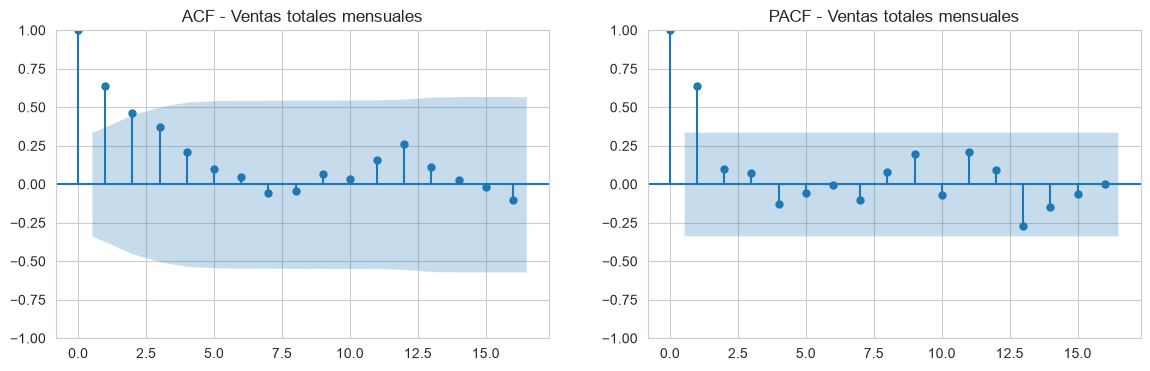

Rezagos significativos ACF : [1, 2]
Rezagos significativos PACF: [1]


In [55]:
serie_total = serie_mensual(df)
graficar_acf_pacf(serie_total, "Ventas totales mensuales", 16)
rezagos_significativos(serie_total, 16)

### Ventas totales (diaria)

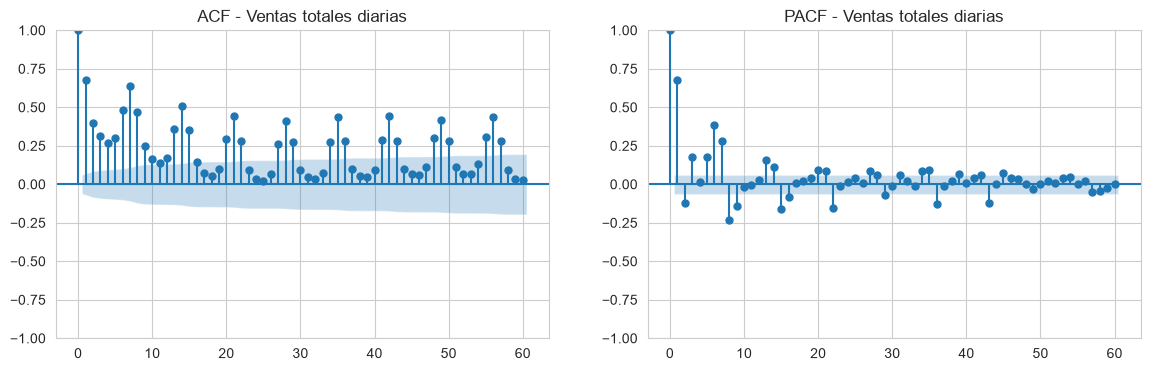

Rezagos significativos ACF : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 21, 22, 27, 28, 29, 34, 35, 36, 41, 42, 43, 48, 49, 50, 55, 56, 57]
Rezagos significativos PACF: [1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 21, 22, 27, 28, 29, 34, 35, 36, 39, 42, 43, 45]


In [56]:
graficar_acf_pacf(ventas_dia, "Ventas totales diarias", 60)
rezagos_significativos(ventas_dia, 60)

### Ventas por sucursal (top 3)

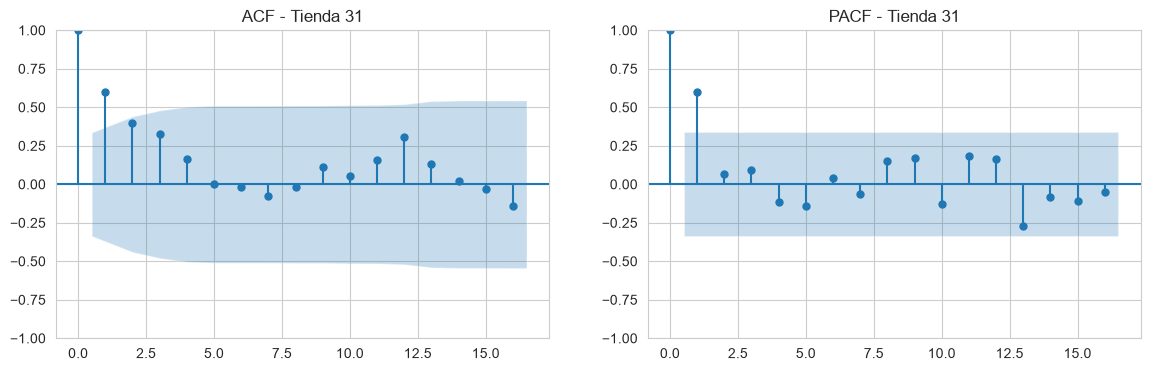

Rezagos significativos ACF : [1]
Rezagos significativos PACF: [1]


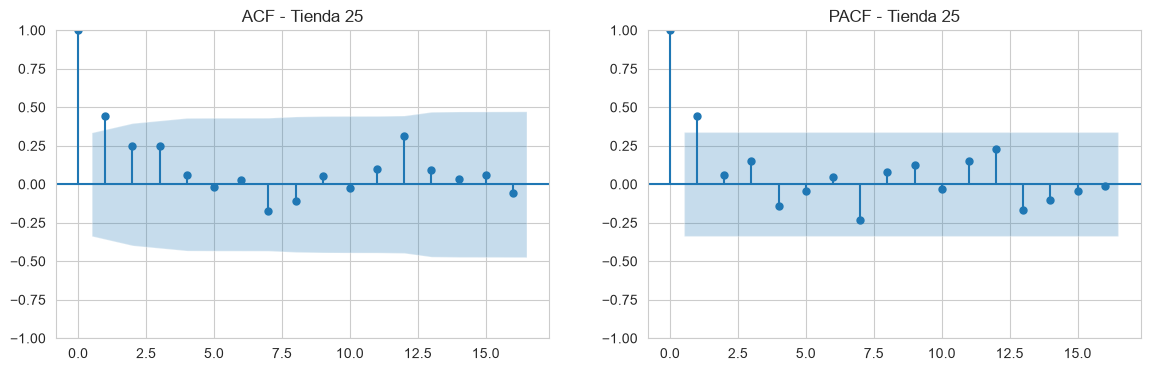

Rezagos significativos ACF : [1]
Rezagos significativos PACF: [1]


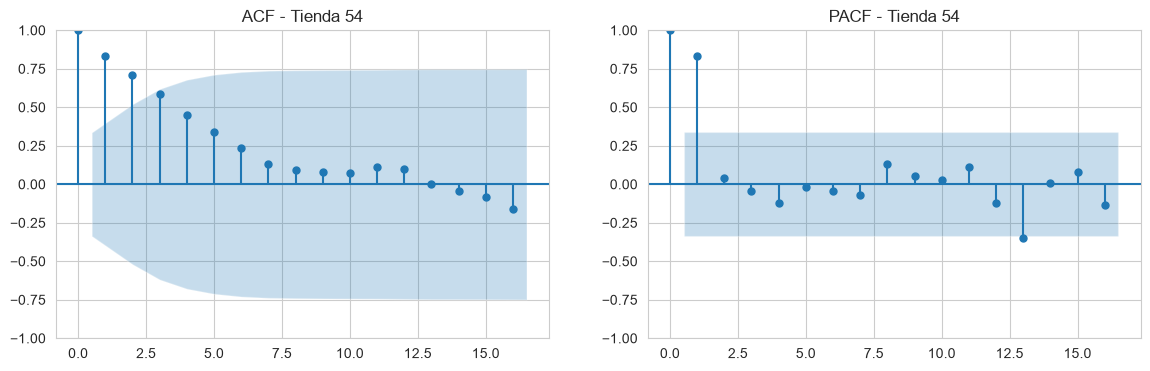

Rezagos significativos ACF : [1, 2]
Rezagos significativos PACF: [1, 13]


In [57]:
top3_tiendas = df.groupby("shop_id")["item_cnt_day"].sum().sort_values(ascending=False).head(3).index

for tienda in top3_tiendas:
    serie = serie_mensual(df[df["shop_id"] == tienda])
    graficar_acf_pacf(serie, "Tienda " + str(tienda), 16)
    rezagos_significativos(serie, 16)

### Ventas por producto (top 3)

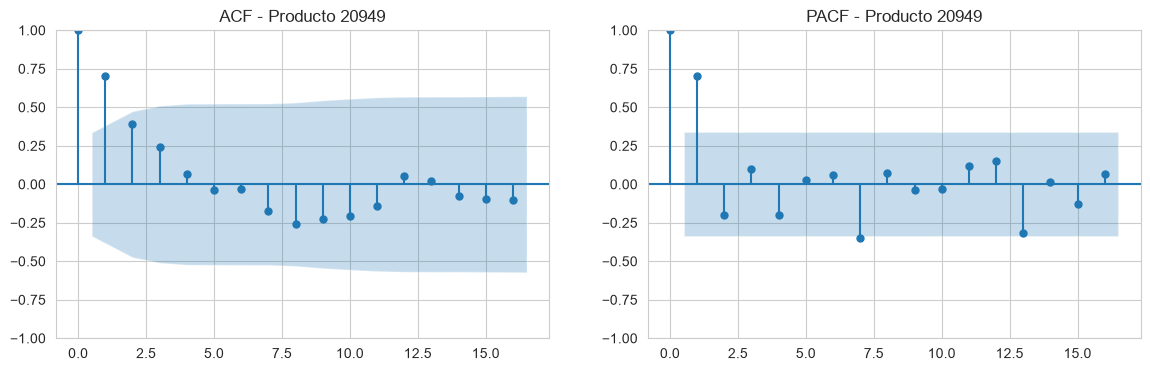

Rezagos significativos ACF : [1]
Rezagos significativos PACF: [1, 7]


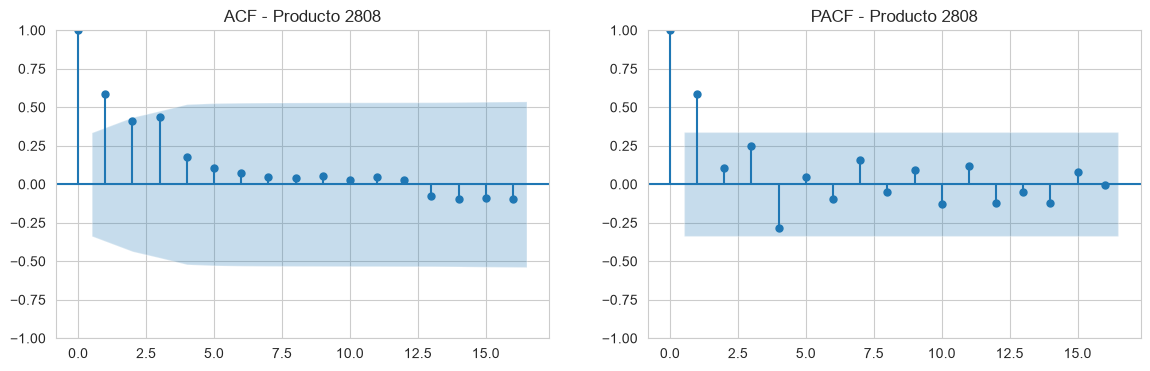

Rezagos significativos ACF : [1]
Rezagos significativos PACF: [1]


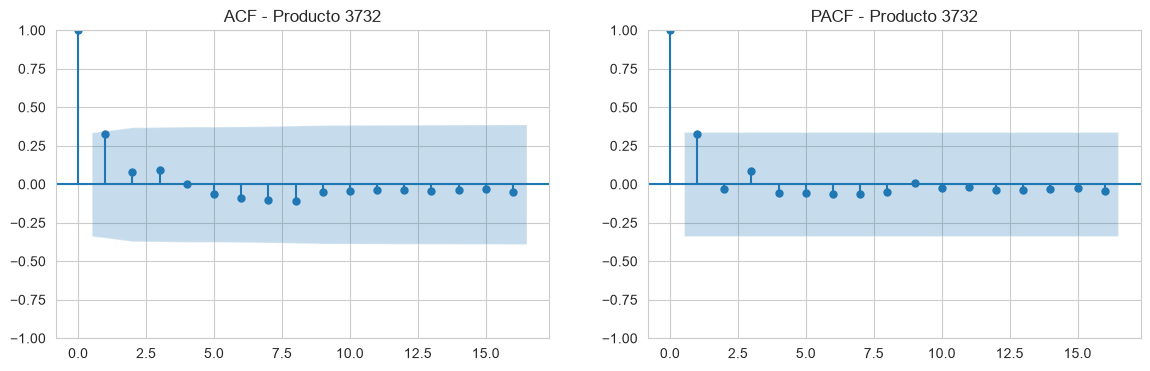

Rezagos significativos ACF : []
Rezagos significativos PACF: []


In [58]:
top3_productos = df.groupby("item_id")["item_cnt_day"].sum().sort_values(ascending=False).head(3).index

for producto in top3_productos:
    serie = serie_mensual(df[df["item_id"] == producto])
    graficar_acf_pacf(serie, "Producto " + str(producto), 16)
    rezagos_significativos(serie, 16)

### Ventas por sucursal-producto (top 3 pares)

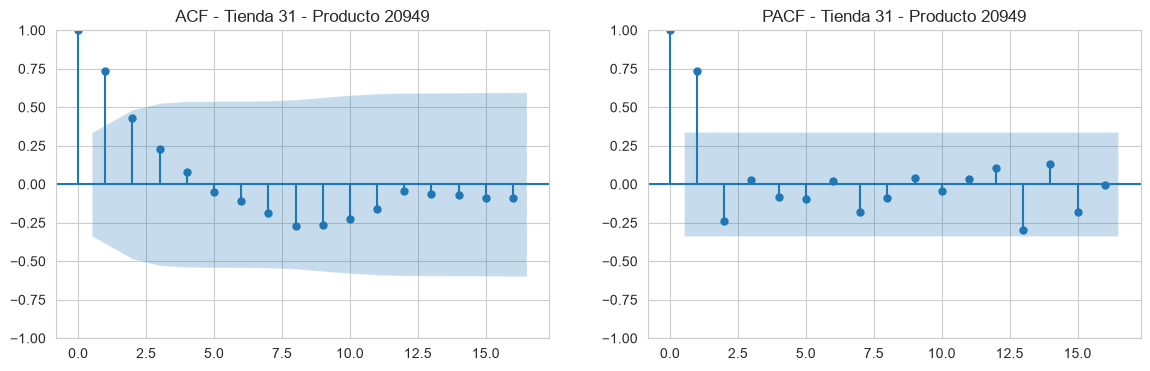

Rezagos significativos ACF : [1]
Rezagos significativos PACF: [1]


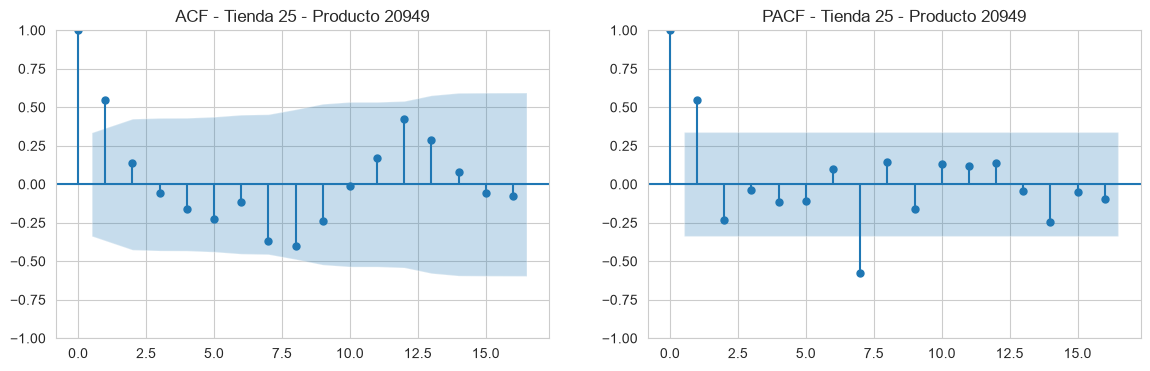

Rezagos significativos ACF : [1]
Rezagos significativos PACF: [1, 7]


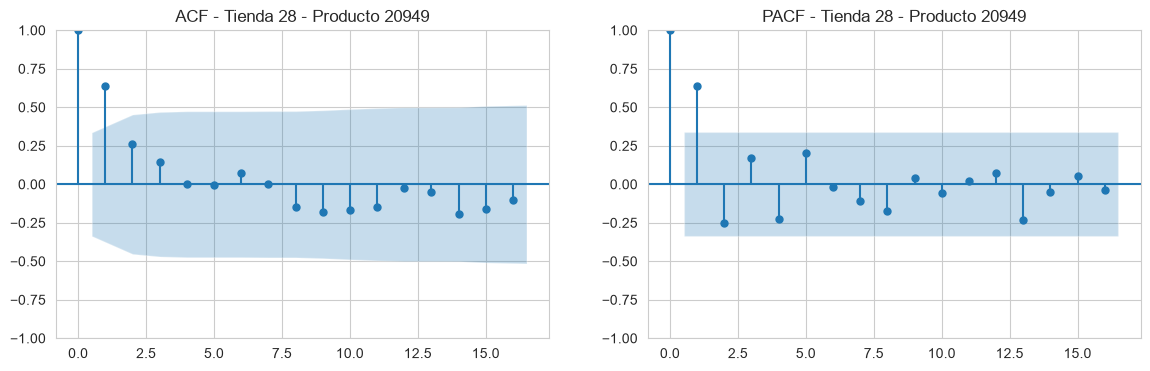

Rezagos significativos ACF : [1]
Rezagos significativos PACF: [1]


In [59]:
top3_pares = df.groupby(["shop_id", "item_id"])["item_cnt_day"].sum().sort_values(ascending=False).head(3).index

for tienda, producto in top3_pares:
    datos_par = df[(df["shop_id"] == tienda) & (df["item_id"] == producto)]
    serie = serie_mensual(datos_par)
    titulo = "Tienda " + str(tienda) + " - Producto " + str(producto)
    graficar_acf_pacf(serie, titulo, 16)
    rezagos_significativos(serie, 16)

**Interpretación (sección 9):**

**i. ¿Existen correlaciones significativas a diferentes rezagos?**

| Serie | ACF significativa | PACF significativa |
|---|---|---|
| Total mensual | 1, 2 | 1 |
| Total diaria | muchos; picos en 7, 14, 21, 28, 35, 42, 49 y 56 | 1, 2, 3, 5-9, ... |
| Tienda 31 | 1 | 1 |
| Tienda 25 | 1 | 1 |
| Tienda 54 | 1, 2 | 1, 13 |
| Producto 20949 | 1 | 1, 7 |
| Producto 2808 | 1 | 1 |
| Producto 3732 | ninguno | ninguno |
| Tienda 31 - producto 20949 | 1 | 1 |
| Tienda 25 - producto 20949 | 1 | 1, 7 |
| Tienda 28 - producto 20949 | 1 | 1 |

- En casi todas las series mensuales el **rezago 1 es significativo** en ACF y PACF: las ventas de un mes dependen
  mucho de las del mes anterior. La ACF baja poco a poco y la PACF se corta después del rezago 1, lo que sugiere un
  modelo **AR(1)**: el dato más útil para pronosticar un mes es el mes anterior.
- El producto **3732** (*GTA V* para PS3) no tiene rezagos significativos porque su serie tiene la forma típica de
  un lanzamiento: 0 ventas hasta el mes 8, un gran pico ese mes (6,972 unidades) y luego una caída rápida. No es una
  serie con un comportamiento que se repita.

**ii. ¿Se observa estacionalidad reflejada en patrones repetitivos?**

- **Semanal (sí):** en la serie diaria la ACF tiene picos claros cada **7 días** (7, 14, 21, ... 56), lo que confirma
  el ciclo semanal visto en la sección 6 (más ventas el fin de semana).
- **Anual (no se puede confirmar con ACF):** aunque en las gráficas se ve el pico de diciembre todos los años, el
  rezago 12 no sale significativo. Con solo 34 meses hay apenas dos ciclos anuales completos, y la banda de
  confianza es muy ancha. Por eso conviene incluir el mes del año como variable en el modelo, en lugar de depender
  del rezago 12.

## 10. Insights y conclusiones del EDA

### Cobertura de `test.csv` respecto al historial de entrenamiento

In [60]:
# Aplicar a test la misma unión de tiendas repetidas (en test solo aparecen 10, 57 y 58, así que no cambia)
pares_train = df[["shop_id", "item_id"]].drop_duplicates()
pares_train["en_train"] = True

cobertura = test.merge(pares_train, on=["shop_id", "item_id"], how="left")
cobertura["en_train"] = cobertura["en_train"].fillna(False)

productos_train = df["item_id"].unique()
tiendas_train = df["shop_id"].unique()

print("Pares de test con historial (misma tienda y producto):",
      round(cobertura["en_train"].mean() * 100, 2), "%")
print("Pares de test cuyo producto se vendió en alguna tienda:",
      round(test["item_id"].isin(productos_train).mean() * 100, 2), "%")
print("Pares de test con producto totalmente nuevo:",
      round((~test["item_id"].isin(productos_train)).mean() * 100, 2), "%")
print("Tiendas de test que existen en train:",
      test["shop_id"].isin(tiendas_train).mean() * 100, "%")
print()
print("Tiendas en test:", test["shop_id"].nunique(), "| Productos en test:", test["item_id"].nunique())

Pares de test con historial (misma tienda y producto): 52.04 %
Pares de test cuyo producto se vendió en alguna tienda: 92.88 %
Pares de test con producto totalmente nuevo: 7.12 %
Tiendas de test que existen en train: 100.0 %

Tiendas en test: 42 | Productos en test: 5100


In [61]:
# ¿Las tiendas de test vendieron en el último mes (octubre 2015)?
tiendas_oct = df[df["date_block_num"] == 33]["shop_id"].unique()
print("Tiendas de test con ventas en octubre 2015:",
      test["shop_id"].drop_duplicates().isin(tiendas_oct).sum(), "de", test["shop_id"].nunique())

Tiendas de test con ventas en octubre 2015: 42 de 42


**Interpretación del cálculo de cobertura:**

- Solo el **52.04%** de los pares tienda-producto de `test` tiene historial de ventas en el train.
- El **92.88%** de los pares corresponde a productos que sí se vendieron en alguna tienda, aunque no en esa tienda.
- El **7.12%** son **productos completamente nuevos**, sin ninguna venta previa.
- Las **42 tiendas** de `test` existen en el train y **todas tuvieron ventas en octubre de 2015**; ninguna de las 13
  tiendas cerradas aparece en `test`.

---

### 10a. Variables que afectan directamente las ventas

- **Ventas del mes anterior:** es la variable con más relación con las ventas del mes siguiente (rezago 1 en ACF y
  PACF de todas las series).
- **Mes del año:** diciembre vende entre 40% y 45% más que noviembre, y enero cae más de 30%.
- **Tendencia general:** las ventas bajan año con año (aproximadamente un 33% en dos años).
- **Tienda:** el tamaño de la tienda cambia mucho el nivel de ventas (de cientos a más de 300,000 unidades), así como
  si es física o en línea (tiendas 12 y 55).
- **Categoría del producto:** las categorías tienen niveles y tendencias distintas (DVD a la baja, PS4 al alza).
- **Precio:** las categorías más caras (consolas) venden menos unidades pero generan más ingresos.
- **Antigüedad del producto:** los productos nuevos tienen un pico en su lanzamiento y luego caen (caso de *GTA V*).

### 10b. Patrones útiles para el modelo de forecasting

- Trabajar a **nivel mensual** por par tienda-producto, rellenando con **0** los meses sin ventas.
- Usar **rezagos** de ventas (1, 2 y 3 meses) y promedios por tienda, producto y categoría.
- Incluir el **mes del año** como variable para captar el pico de diciembre. Noviembre (el mes a predecir) es
  históricamente un mes alto (130,009 unidades en 2013 y 117,845 en 2014), pero no tanto como diciembre.
- Considerar la **tendencia a la baja**: noviembre de 2015 probablemente venda menos que noviembre de 2014.
- **Cobertura de test:** como solo el 52.04% de los pares tiene historial y el 7.12% son productos nuevos, el modelo
  necesita variables que no dependan del par exacto (categoría, tienda, primer mes de venta del producto). Así puede
  estimar ventas para pares sin historia.

### 10c. Calidad y preparación del dataset

- **Calidad buena:** no hay nulos, no faltan días, `date_block_num` coincide con la fecha en el 100% de las filas y
  solo hubo que corregir 7 filas (1 precio negativo y 6 duplicados).
- **Correcciones necesarias:** unir las tiendas repetidas (0→57, 1→58, 11→10), conservar las devoluciones como venta
  neta y recortar la variable objetivo a [0, 20].
- **Puntos de atención:** hay valores extremos reales (licencias, envíos, bolsas y servicios de pago en tiendas en
  línea) y tiendas que abrieron o cerraron durante el periodo. Todo esto debe tenerse en cuenta al construir las
  variables del modelo.
- En general, el dataset está **listo para la etapa de feature engineering y modelado**, con la limpieza descrita
  en la sección 4.